In [3]:
import numpy as np
from matplotlib import pyplot as plt
import imutils
import matplotlib.cm as cm
import ipywidgets as widgets
from IPython.display import display, clear_output
from skimage import data
import glob
import open3d as o3d
import copy
from sklearn.linear_model import LinearRegression
from mpl_toolkits.mplot3d import Axes3D
from sklearn.cluster import KMeans, k_means
from sklearn import linear_model
from IPython.display import Image, display
from math import *
from scipy import ndimage, signal
import sklearn as sk
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
import pandas as pd
from sklearn.decomposition import PCA
import math
import time
import datetime as dt
from sklearn import datasets, svm, metrics
from sklearn.datasets import fetch_openml
import ssl
from sklearn.datasets import fetch_lfw_people
from sklearn.neighbors import KNeighborsClassifier
from tqdm import tqdm
from sklearn.model_selection import LeaveOneOut, KFold, StratifiedKFold
import cv2
from numpy.linalg import inv, pinv

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


# Working area

In [4]:
def CalibrateStereoCamera():

    # -----
    img = cv2.imread("0_calib/left/000.png")
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    h, w = img.shape[:2]
    image_size = (w,h)

    # -----
    nb_vertical = 5
    nb_horizontal = 7

    image_range = 37
    def get_filename(idx: int):
        return f"0_calib/left/{idx:03d}.png", f"0_calib/right/{idx:03d}.png"

    # Prepare object points, like (0, 0, 0), (1, 0, 0), (2, 0, 0) ....,(6, 5, 0).
    objp = np.zeros((nb_horizontal * nb_vertical, 3), np.float32)
    objp[:, :2] = np.mgrid[0:nb_vertical, 0:nb_horizontal].T.reshape(-1, 2)

    # Arrays to store object points and image points from all the images.
    objpoints = []  # 3D point in real world space.
    imgpoints_left = []  # 2D points in image plane.
    imgpoints_right = []  # 2D points in image plane.

    skip_images = [4,6,7,14,17]

    for image_idx in range(image_range):

        if image_idx in skip_images:
            continue

        fname_left, fname_right = get_filename(image_idx)

        img_left = cv2.imread(fname_left)
        img_right = cv2.imread(fname_right)

        ret_left, corners_left = cv2.findChessboardCornersSB(
            img_left, (nb_vertical, nb_horizontal), None
        )

        ret_right, corners_right = cv2.findChessboardCornersSB(
            img_right, (nb_vertical, nb_horizontal), None
        )

        # If found, add object points, image points (after refining them).
        if not (ret_left and ret_right):
            continue

        objpoints.append(objp.copy())
        imgpoints_left.append(corners_left)
        imgpoints_right.append(corners_right)

    

    rms_left, K_left, dist_left, rvecs_left, tvecs_left = cv2.calibrateCamera(
        objpoints, imgpoints_left, image_size, None, None
    )

    rms_right, K_right, dist_right, rvecs_right, tvecs_right = cv2.calibrateCamera(
        objpoints, imgpoints_right, image_size, None, None
    )

    rms_stereo, K_left, dist_left, K_right, dist_right, R, T, E, F = cv2.stereoCalibrate(
        objpoints,
        imgpoints_left, imgpoints_right,
        K_left, dist_left,
        K_right, dist_right,
        image_size,
        flags=cv2.CALIB_FIX_INTRINSIC
    )

    R1, R2, P1, P2, Q, roi1, roi2 = cv2.stereoRectify(
        K_left, dist_left,
        K_right, dist_right,
        image_size,
        R, T,
        flags=cv2.CALIB_ZERO_DISPARITY,
        alpha=0
    )

    mapLx, mapLy = cv2.initUndistortRectifyMap(K_left, dist_left, R1, P1, (w,h), cv2.CV_32FC1)
    mapRx, mapRy = cv2.initUndistortRectifyMap(K_right, dist_right, R2, P2, (w,h), cv2.CV_32FC1)

    np.savez_compressed("calibration_maps.npz",
        mapLx=mapLx,
        mapLy=mapLy,
        mapRx=mapRx,
        mapRy=mapRy,
        Q=Q,
    )
    display(f"Stereo calibration completed. RMS error: {rms_stereo:.4f}")
    return True



def load_and_undistort_images(image_folder, format=cv2.COLOR_BGR2RGB):
    """
    Loads and undistorts images from the specified folder using precomputed calibration maps.
    
    Parameters:
    - image_folder: Path to the folder containing 'left' and 'right' subfolders with images.
    - format: cv2.COLOR_BGR2* format to convert the images to (default is cv2.COLOR_BGR2RGB).

    Returns:
    - undistorted_images_left: List of undistorted left camera images, in chosen format.
    - undistorted_images_right: List of undistorted right camera images, in chosen format.
    - undistorted_images_left_gray: List of undistorted left camera images in grayscale.
    - undistorted_images_right_gray: List of undistorted right camera images in grayscale
    """
    calibration_maps = np.load("calibration_maps.npz")

    mapLx = calibration_maps["mapLx"]
    mapLy = calibration_maps["mapLy"]
    mapRx = calibration_maps["mapRx"]
    mapRy = calibration_maps["mapRy"]
    # Load all images from the specified folder
    image_files_left = sorted(glob.glob(f"{image_folder}/left/*.png"))
    image_files_right = sorted(glob.glob(f"{image_folder}/right/*.png"))    

    undistorted_images_left = []

    for image_file in image_files_left:
        # Read the image
        img = cv2.imread(image_file)
        if img is None:
            print(f"Warning: Could not read image {image_file}. Skipping.")
            continue

        # Undistort the image using the provided maps
        undistorted_img = cv2.remap(img, mapLx, mapLy, interpolation=cv2.INTER_LINEAR)
        undistorted_images_left.append(undistorted_img)

    undistorted_images_right = []
    
    for image_file in image_files_right:
        # Read the image
        img = cv2.imread(image_file)
        if img is None:
            print(f"Warning: Could not read image {image_file}. Skipping.")
            continue

        # Undistort the image using the provided maps
        undistorted_img = cv2.remap(img, mapRx, mapRy, interpolation=cv2.INTER_LINEAR)
        undistorted_images_right.append(undistorted_img)

    
    undistorted_images_left_gray = [cv2.cvtColor(img, cv2.COLOR_BGR2GRAY) for img in undistorted_images_left]
    undistorted_images_right_gray = [cv2.cvtColor(img, cv2.COLOR_BGR2GRAY) for img in undistorted_images_right]
    undistorted_images_left = [cv2.cvtColor(img, format) for img in undistorted_images_left]
    undistorted_images_right = [cv2.cvtColor(img, format) for img in undistorted_images_right]

    return undistorted_images_left, undistorted_images_right, undistorted_images_left_gray, undistorted_images_right_gray


In [ ]:
calibration_success = CalibrateStereoCamera()
display(calibration_success)

720 1280


True

In [ ]:
# undistL, undistR, undistLg, undistRg = load_and_undistort_images('1_no_obstacle')
undistL, undistR, undistLg, undistRg = load_and_undistort_images('4_circle')

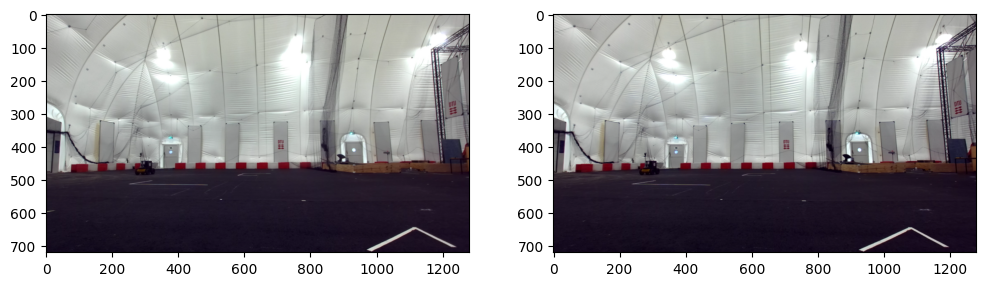

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].imshow(undistL[100])
ax[1].imshow(undistR[100])

### optical flow to track 

In [13]:
undistL, undistR, undistLg, undistRg = load_and_undistort_images('1_no_obstacle')

In [ ]:
def detect_robot_dense_optical(undistL, undistLg, undistR, undistRg):
    '''
    Detects the robot in a sequence of undistorted grayscale images
    by computing optical flow and generating masks based on the magnitude of the flow.

    parameters:
    - folder: Path to the folder containing the images. as string

    returns:
    - masks: List of masks only indicating the detected robot regions in each frame.
    '''
    
    
    flows = []
    magnitudes = []

    # loop through the undistorted grayscale images to compute optical flow
    # for i in range(len(undistLg) - 1):
    for i in range(90, 100):
        gray1 = undistLg[i]
        gray2 = undistLg[i + 1]

        if i >= 91:
            gray1 = roi & gray1
            gray2 = roi & gray2
            plt.figure(figsize=(10, 6))
            plt.imshow(gray2)

        # get Optical flow
        flow = cv2.calcOpticalFlowFarneback(
            gray1, gray2,
            None,
            0.5, 3, 15, 3, 5, 1.5, 0
        )

        # convert flow to polar coordinates to get magnitude and angle
        mag,theta = cv2.cartToPolar(flow[..., 0], flow[..., 1])

        flows.append(flow)
        magnitudes.append(mag)

        # get region of interest (ROI) for the robot based on the magnitude of the flow
        roi = (mag > 2.0).astype(np.uint8) * 255
        kernel2 = np.ones((3, 3), np.uint8)
        roi = cv2.morphologyEx(roi, cv2.MORPH_OPEN, kernel2)


    # Create masks based on the magnitude of the optical flow
    threshold = 2.0
    kernel2 = np.ones((3, 3), np.uint8)
    masks = [
        (magnitude > threshold).astype(np.uint8) * 255
        for magnitude in magnitudes
    ]

    # do opening and closing to remove noise and fill gaps in the masks
    masks = [cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel2) for mask in masks]
    masks = [cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel2) for mask in masks]
    return masks

array([[5.5342600e-02, 6.6837691e-02, 8.2916774e-02, ..., 2.2270028e-03,
        7.6880172e-04, 1.7052962e-04],
       [7.8978002e-02, 9.8034658e-02, 1.1737013e-01, ..., 2.5073395e-03,
        1.0130490e-03, 2.3448360e-04],
       [1.0935532e-01, 1.3599141e-01, 1.5464592e-01, ..., 2.5637022e-03,
        1.0334845e-03, 2.4382629e-04],
       ...,
       [2.4697161e-04, 2.9247528e-04, 3.2940789e-04, ..., 1.1383920e-03,
        6.9508958e-04, 3.4775594e-04],
       [1.5519427e-04, 1.8682882e-04, 2.2606459e-04, ..., 6.7508890e-04,
        5.3157413e-04, 2.9197425e-04],
       [1.3260386e-04, 1.6774083e-04, 1.9734667e-04, ..., 2.4419639e-04,
        3.2189343e-04, 1.8396624e-04]], shape=(720, 1280), dtype=float32)

array([[0.0000000e+00, 0.0000000e+00, 0.0000000e+00, ..., 0.0000000e+00,
        0.0000000e+00, 0.0000000e+00],
       [0.0000000e+00, 0.0000000e+00, 0.0000000e+00, ..., 0.0000000e+00,
        0.0000000e+00, 0.0000000e+00],
       [0.0000000e+00, 0.0000000e+00, 0.0000000e+00, ..., 0.0000000e+00,
        0.0000000e+00, 0.0000000e+00],
       ...,
       [1.3277258e-14, 2.3154803e-14, 3.0044679e-14, ..., 0.0000000e+00,
        0.0000000e+00, 0.0000000e+00],
       [1.3277258e-14, 2.3154803e-14, 3.0044679e-14, ..., 0.0000000e+00,
        0.0000000e+00, 0.0000000e+00],
       [1.3277258e-14, 2.3154803e-14, 3.0044679e-14, ..., 0.0000000e+00,
        0.0000000e+00, 0.0000000e+00]], shape=(720, 1280), dtype=float32)

array([[0.0000000e+00, 0.0000000e+00, 0.0000000e+00, ..., 0.0000000e+00,
        0.0000000e+00, 0.0000000e+00],
       [0.0000000e+00, 0.0000000e+00, 0.0000000e+00, ..., 0.0000000e+00,
        0.0000000e+00, 0.0000000e+00],
       [0.0000000e+00, 0.0000000e+00, 0.0000000e+00, ..., 0.0000000e+00,
        0.0000000e+00, 0.0000000e+00],
       ...,
       [3.9013349e-18, 7.1421818e-18, 5.3513427e-17, ..., 0.0000000e+00,
        0.0000000e+00, 0.0000000e+00],
       [3.9013349e-18, 7.1421818e-18, 5.3513427e-17, ..., 0.0000000e+00,
        0.0000000e+00, 0.0000000e+00],
       [3.9013349e-18, 7.1421818e-18, 5.3513427e-17, ..., 0.0000000e+00,
        0.0000000e+00, 0.0000000e+00]], shape=(720, 1280), dtype=float32)

array([[0.0000000e+00, 0.0000000e+00, 0.0000000e+00, ..., 0.0000000e+00,
        0.0000000e+00, 0.0000000e+00],
       [0.0000000e+00, 0.0000000e+00, 0.0000000e+00, ..., 0.0000000e+00,
        0.0000000e+00, 0.0000000e+00],
       [0.0000000e+00, 0.0000000e+00, 0.0000000e+00, ..., 0.0000000e+00,
        0.0000000e+00, 0.0000000e+00],
       ...,
       [4.9164620e-20, 3.1276332e-19, 3.1067580e-18, ..., 0.0000000e+00,
        0.0000000e+00, 0.0000000e+00],
       [4.9164620e-20, 3.1276332e-19, 3.1067580e-18, ..., 0.0000000e+00,
        0.0000000e+00, 0.0000000e+00],
       [4.9164620e-20, 3.1276332e-19, 3.1067580e-18, ..., 0.0000000e+00,
        0.0000000e+00, 0.0000000e+00]], shape=(720, 1280), dtype=float32)

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], shape=(720, 1280), dtype=float32)

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], shape=(720, 1280), dtype=float32)

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], shape=(720, 1280), dtype=float32)

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], shape=(720, 1280), dtype=float32)

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], shape=(720, 1280), dtype=float32)

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], shape=(720, 1280), dtype=float32)

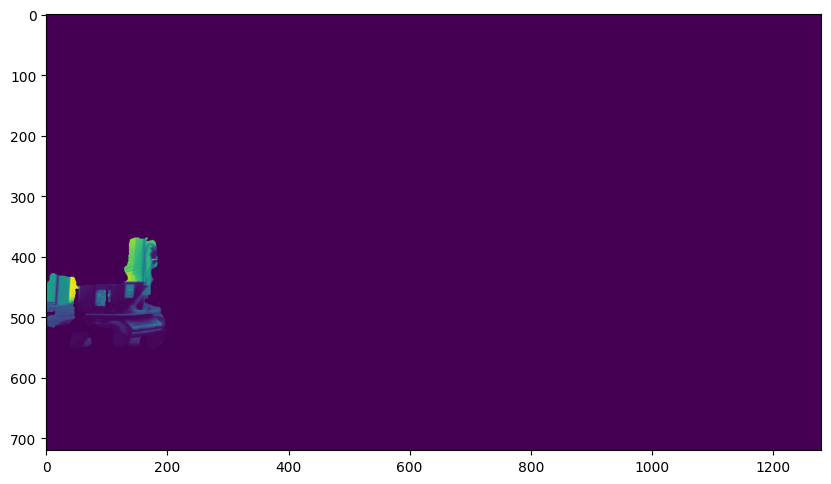

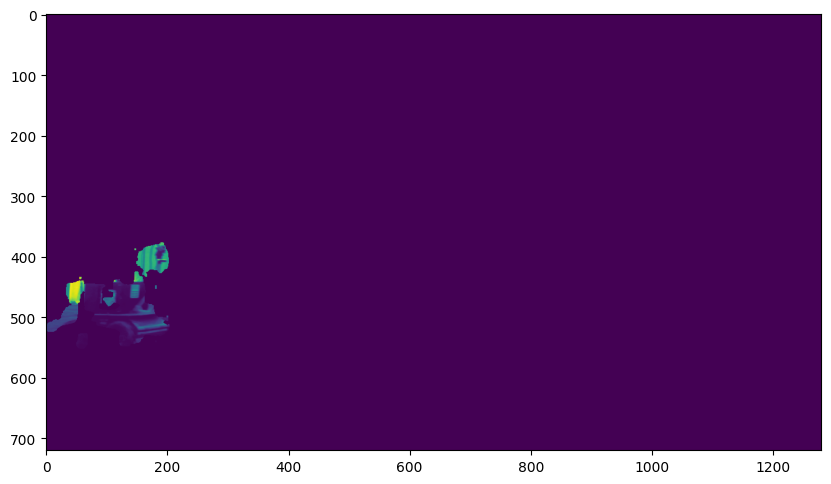

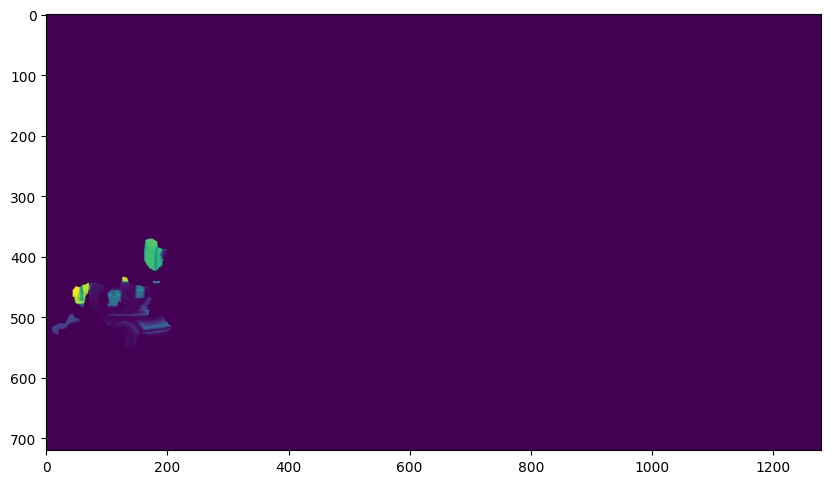

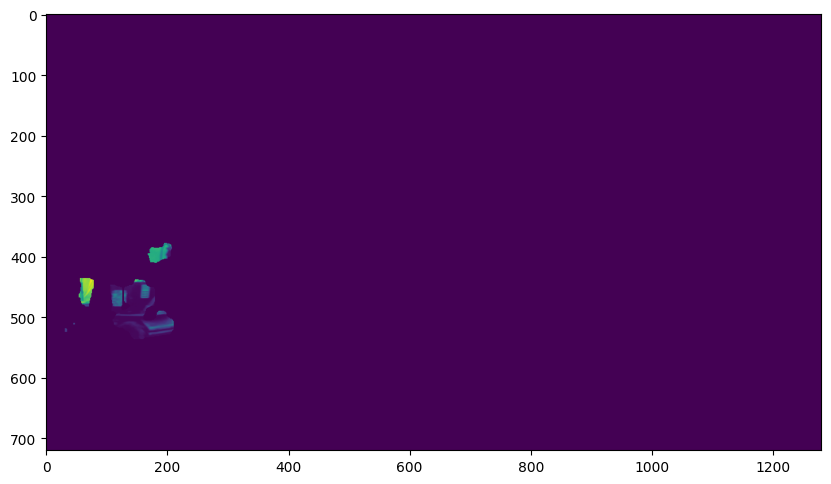

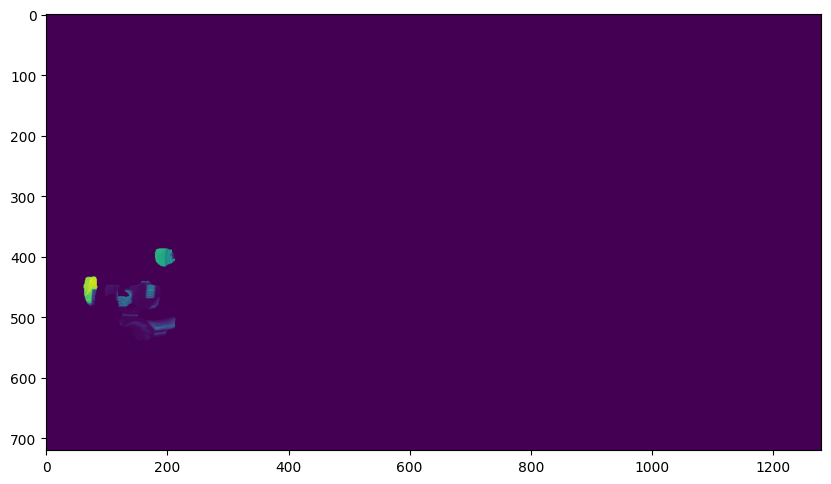

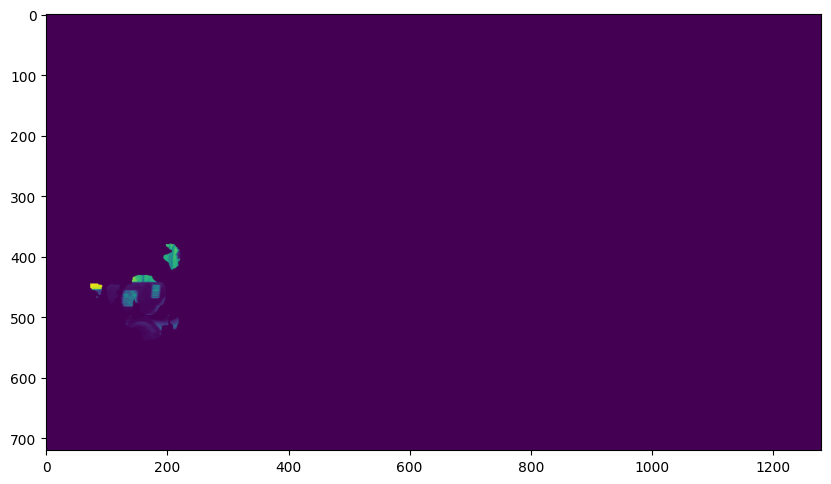

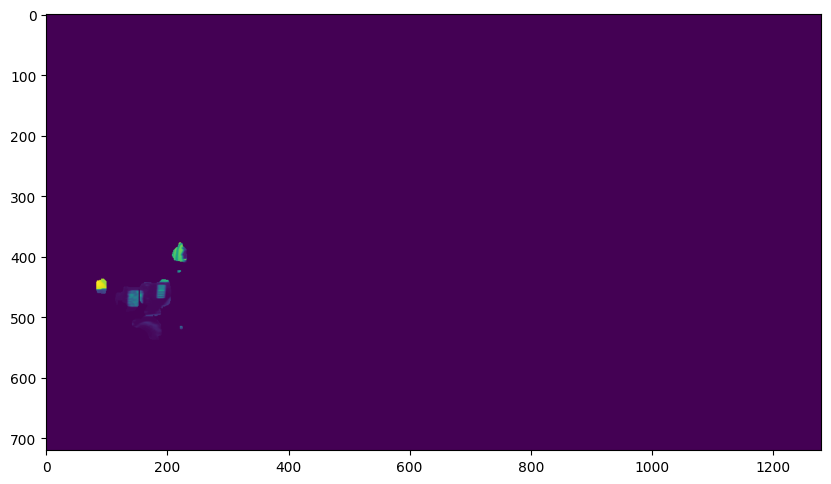

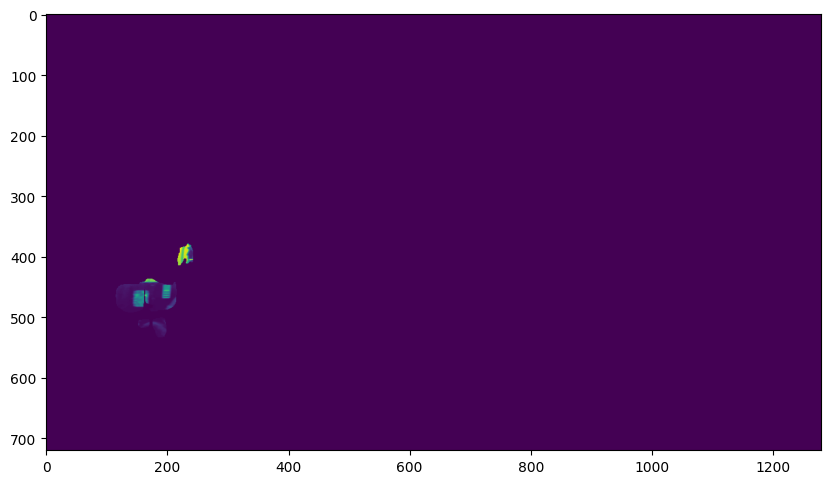

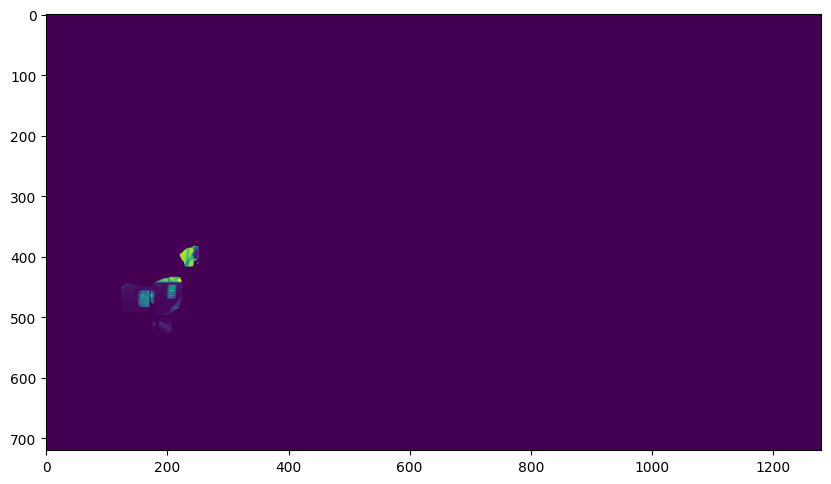

In [19]:
Masks = detect_robot_dense_optical(undistL, undistLg, undistR, undistRg)

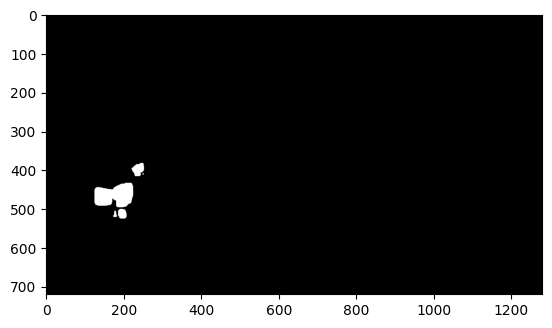

In [22]:
plt.imshow(Masks[8], cmap='gray')

In [ ]:

    outputs = []
    
    for i, mask in enumerate(masks):

        # Find contours
        cnts = cv2.findContours(
            mask.copy(),
            cv2.RETR_EXTERNAL,
            cv2.CHAIN_APPROX_SIMPLE
        )

        cnts = imutils.grab_contours(cnts)

        # Filter small contours
        large_contours = [
            contour for contour in cnts
            if cv2.contourArea(contour) > 10000
        ]

        # Corresponding original frame
        output = undistL[i + 1].copy()

        # Draw bounding boxes
        for contour in large_contours:
            x, y, w, h = cv2.boundingRect(contour)

            cv2.rectangle(
                output,
                (x, y),
                (x + w, y + h),
                (0, 255, 0),
                2
            )

        cv2.imshow("Motion Detection", output)
        if cv2.waitKey(20) & 0xFF == ord('q'):
            break
        outputs.append(output)

    cv2.destroyAllWindows()
    cv2.waitKey(1)

    return True


### box

In [ ]:
flows = []
magnitudes = []

for i in range(len(undistLg) - 1):

    gray1 = undistLg[i]
    gray2 = undistLg[i + 1]

    # Optical flow
    flow = cv2.calcOpticalFlowFarneback(
        gray1, gray2,
        None,
        0.5, 3, 15, 3, 5, 1.5, 0
    )

    mag,theta = cv2.cartToPolar(flow[..., 0], flow[..., 1])

    flows.append(flow)
    magnitudes.append(mag)

threshold = 2.0
kernel2 = np.ones((11, 11), np.uint8)
masks = [
    (magnitude > threshold).astype(np.uint8) * 255
    for magnitude in magnitudes
]

masks = [cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel2)for mask in masks]
masks = [cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel2)for mask in masks]

In [ ]:
outputs = []

for i, mask in enumerate(masks):

    # Find contours
    cnts = cv2.findContours(
        mask.copy(),
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    cnts = imutils.grab_contours(cnts)

    # Filter small contours
    large_contours = [
        contour for contour in cnts
        if cv2.contourArea(contour) > 10000
    ]

    # Corresponding original frame
    output = undistL[i + 1].copy()

    # Draw bounding boxes
    for contour in large_contours:
        x, y, w, h = cv2.boundingRect(contour)

        cv2.rectangle(
            output,
            (x, y),
            (x + w, y + h),
            (0, 255, 0),
            2
        )

    cv2.imshow("Motion Detection", output)
    if cv2.waitKey(20) & 0xFF == ord('q'):
        break
    outputs.append(output)

cv2.destroyAllWindows()
cv2.waitKey(1)


-1

sparse gray

In [ ]:
idx = 0
gray1 = undistLg[idx]

while True:

    gray2 = undistLg[idx+1]

    # find features to track
    feat1 = cv2.goodFeaturesToTrack(gray1, maxCorners=100, qualityLevel=0.2, minDistance=5)
    feat2, status, error = cv2.calcOpticalFlowPyrLK(gray1, gray2, feat1, None)

    # display moving features on video
    img_op = gray2.copy()
    threshold = 2
    for i in range(len(feat1)):
        f10=int(feat1[i][0][0])
        f11=int(feat1[i][0][1])
        f20=int(feat2[i][0][0])
        f21=int(feat2[i][0][1])
        if abs(f10-f20) >= threshold or abs(f11-f21) >= threshold:
            cv2.line(img_op, (f10,f11), (f20, f21), (0, 255, 0), 2)
            cv2.circle(img_op, (f10, f11), 5, (0, 255, 0), -1)

    # display image
    cv2.imshow('image', img_op)

    if cv2.waitKey(20) & 0xFF == ord('q'):
        break

    # done processing, update last frame
    gray1 = gray2
    idx += 1
    

cv2.destroyAllWindows()
cv2.waitKey(1)

IndexError: list index out of range

In [ ]:
# Sparse optical flow with static-feature filtering
last_frame = len(undistL) - 1
first_frame = undistL[0]
previous_gray = undistLg[0]

previous_points = cv2.goodFeaturesToTrack(
    previous_gray,
    maxCorners=200,
    qualityLevel=0.3,
    minDistance=7,
    blockSize=7
)

if previous_points is None:
    raise RuntimeError("No trackable features were found.")

motion_threshold = 1.0
maximum_static_frames = 30

# One counter for each tracked feature
static_frame_counts = np.zeros(len(previous_points), dtype=int)

lk_parameters = dict(
    winSize=(15, 15),
    maxLevel=2,
    criteria=(
        cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT,
        10,
        0.03
    )
)

idx = 1

while idx <= last_frame:
    frame = undistL[idx]
    current_gray = undistLg[idx]

    current_points, status, error = cv2.calcOpticalFlowPyrLK(
        previous_gray,
        current_gray,
        previous_points,
        None,
        **lk_parameters
    )

    # if current_points is None or status is None:
    #     break

    # Keep only successfully tracked points
    valid_mask = status.ravel() == 1

    valid_previous = previous_points[valid_mask].reshape(-1, 2)
    valid_current = current_points[valid_mask].reshape(-1, 2)
    valid_static_counts = static_frame_counts[valid_mask]

    # Calculate movement in pixels
    displacement = valid_current - valid_previous
    movement = np.linalg.norm(displacement, axis=1)

    # Increase the counter if movement is less than 1 pixel.
    # Reset it when the feature moves at least 1 pixel.
    valid_static_counts = np.where(
        movement < motion_threshold,
        valid_static_counts + 1,
        0
    )

    # Remove features static for 30 consecutive frames
    keep_mask = valid_static_counts < maximum_static_frames

    kept_previous = valid_previous[keep_mask]
    kept_current = valid_current[keep_mask]
    kept_static_counts = valid_static_counts[keep_mask]
    kept_movement = movement[keep_mask]

    # Display only features that moved at least 1 pixel
    for previous_point, current_point, movement_value in zip(
        kept_previous,
        kept_current,
        kept_movement
    ):
        if movement_value >= motion_threshold:
            x_previous, y_previous = previous_point.astype(int)
            x_current, y_current = current_point.astype(int)

            cv2.line(
                frame,
                (x_previous, y_previous),
                (x_current, y_current),
                (0, 255, 0),
                2
            )

            cv2.circle(
                frame,
                (x_current, y_current),
                4,
                (0, 0, 255),
                -1
            )

    cv2.imshow("Sparse optical flow", frame)

    # Press q to stop
    if cv2.waitKey(20) & 0xFF == ord("q"):
        break

    previous_gray = current_gray
    idx += 1

    # Detect new features if too few tracked features remain
    if len(kept_current) < 30:
        previous_points = cv2.goodFeaturesToTrack(
            previous_gray,
            maxCorners=200,
            qualityLevel=0.3,
            minDistance=7,
            blockSize=7
        )

        if previous_points is None:
            break

        static_frame_counts = np.zeros(len(previous_points), dtype=int)

    else:
        previous_points = kept_current.reshape(-1, 1, 2)
        static_frame_counts = kept_static_counts

cv2.destroyAllWindows()
cv2.waitKey(1)

-1

In [ ]:
def detect_robot_kalman(folder):
    undistL, undistR, undistLg, undistRg = load_and_undistort_images(folder)

    # Initialize Kalman filter
    kalman = cv2.KalmanFilter(4, 2)
    kalman.measurementMatrix = np.array([[1, 0, 0, 0], [0, 1, 0, 0]], np.float32)
    kalman.transitionMatrix = np.array([[1, 0, 1, 0], [0, 1, 0, 1], [0, 0, 1, 0], [0, 0, 0, 1]], np.float32)
    kalman.processNoiseCov = np.eye(4) * 0.03
    
    last_measurement = None
    last_prediction = None

    for i in range(len(undistLg) - 1):
        gray1 = undistLg[i]
        gray2 = undistLg[i + 1]

        # Get optical flow
        flow = cv2.calcOpticalFlowFarneback(
            gray1, gray2,
            None,
            0.5, 3, 15, 3, 5, 1.5, 0
        )

        mag, theta = cv2.cartToPolar(flow[..., 0], flow[..., 1])

        # Create mask based on magnitude
        threshold = 2.0
        mask = (mag > threshold).astype(np.uint8) * 255

        # Morphological operations to clean up the mask
        kernel2 = np.ones((11, 11), np.uint8)
        mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel2)
        mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel2)

        # Find contours
        cnts = cv2.findContours(mask.copy(), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cnts = imutils.grab_contours(cnts)

        # Filter large contours
        large_contours = [contour for contour in cnts if cv2.contourArea(contour) > 10000]

        output = undistL[i + 1].copy()

        for contour in large_contours:
            x, y, w, h =

In [ ]:
# cap = cv2.VideoCapture('rolling_ball.mp4')
# fps = cap.get(cv2.CAP_PROP_FPS)
# t = 1.0 / fps

I = np.eye(6)  # Identity matrix for covariance update
def Update(x, P, Z, H, R):
    """
    Kalman measurement update — fuse a new observation Z into the current
    state estimate x and covariance P.

    Steps:
      y = z - H·x        Innovation: how far off was our prediction?
      S = H·P·Hᵀ + R     Innovation covariance (uncertainty of the prediction in measurement space)
      K = P·Hᵀ·S⁻¹       Kalman gain: how much to trust the measurement vs. the model
      x = x + K·y        Nudge state toward the measurement, weighted by K
      P = (I - K·H)·P    Reduce uncertainty — we've gained information
    """
    y = Z - H @ x                          # Innovation
    S = H @ P @ H.T + R             # Innovation covariance
    K = P @ H.T @ np.linalg.pinv(S) # Kalman gain
    x = x + K @ y                          # State update
    P = (I - K @ H) @ P             # Covariance update
    return [x, P]

dt = t

sigma_j = 0.5  # Standard deviation of jerk (tune this)

Q_axis = np.array([
    [dt**6/36, dt**5/12, dt**4/6],
    [dt**5/12, dt**4/4,  dt**3/2],
    [dt**4/6,  dt**3/2,  dt**2]
]) * sigma_j**2

Q = np.zeros((6, 6))
Q[:3, :3] = Q_axis
Q[3:, 3:] = Q_axis

def predict(x, P, F, u, Q):
    """
    Kalman prediction step — project the state forward one timestep using
    the motion model F and control input u.

    Steps:
      x = F·x + u    Apply physics: advance position by current velocity
      P = F·P·Fᵀ     Propagate uncertainty (grows because we're extrapolating)

    Note: a full implementation would add process noise Q here (P = F·P·Fᵀ + Q),
    but Q=0 is assumed (perfect motion model).
    """
    x = F@x + u          # Predict next state
    P = F@P@ F.T +Q # Predict next covariance
    return [x, P]
    
    
### Initialize Kalman filter ###
# The initial state (6x1).
x = np.array([[0],
              [0],
              [0],
              [0],
              [0],
              [0]])

# The initial uncertainty (6x6).
P = np.eye(6) * 1000  # Large initial uncertainty

# The external motion (6x1).
u = np.array([[0],
              [0],
              [0],
              [0],
              [0],
              [0]])

# The transition matrix (6x6). 
F = np.array([[1, t, 0.5*t**2, 0, 0, 0],
              [0, 1, t, 0, 0, 0],
              [0, 0, 1, 0, 0, 0],
              [0, 0, 0, 1, t, 0.5*t**2],
              [0, 0, 0, 0, 1, t],
              [0, 0, 0, 0, 0, 1]])

# The observation matrix (2x6).
H = np.array([[1, 0, 0, 0, 0, 0],
              [0, 0, 0, 1, 0, 0]])

# The measurement uncertainty.
R = np.eye(2)

# Load the video
if not cap.isOpened():
    print("Cannot open video")
    exit()

# Looping through all the frames
r1 = 0  # Initialize radius variable
frames=[]
while True:
    ret, frame = cap.read()
    if not ret:
        break
    ### Detect the ball ###
    circles = detect_ball_2(frame)
    ### If the ball is found, update the Kalman filter ###

    if circles is not None:
        x1,y1,r1 = circles[0][0]
        x, P = update(x, P, np.array([[x1],[y1]]), H, R)

    ### Predict the next state
    x_pred, P_pred = predict(x, P, F, u,Q)
    
    
    ### Draw the current tracked state and the predicted state on the image frame ###
    cv2.circle(frame, (int(x[0, 0]), int(x[3, 0])), int(r1), (0, 255, 0), 3)
    cv2.circle(frame, (int(x_pred[0, 0]), int(x_pred[3, 0])), int(r1), (0, 0, 255), 3)
    # Display Kalman filter state
    font = cv2.FONT_HERSHEY_SIMPLEX
    font_scale = 0.8
    color = (0, 0, 0)  # Black text
    thickness = 2
    x, P = x_pred, P_pred  # Update the state and covariance for the next iteration

    cv2.putText(frame, f"Predicted Position:     x = {x[0,0]:.1f}  y = {x[3,0]:.1f}",
                (20, 40), font, font_scale, color, thickness)

    cv2.putText(frame, f"Predicted Velocity:     x = {x[1,0]:.1f}  y = {x[4,0]:.1f}",
                (20, 80), font, font_scale, color, thickness)

    cv2.putText(frame, f"Predicted Acceleration: x = {x[2,0]:.1f}  y = {x[5,0]:.1f}",
                (20, 120), font, font_scale, color, thickness)

    # Circle legend
    font = cv2.FONT_HERSHEY_SIMPLEX
    font_scale = 0.7
    thickness = 2

    # Current state (green)
    cv2.circle(frame, (30, 160), 8, (0, 255, 0), -1)
    cv2.putText(frame, "Current state", (50, 167),
                font, font_scale, (0, 0, 0), thickness)

    # Predicted state (red)
    cv2.circle(frame, (30, 195), 8, (0, 0, 255), -1)
    cv2.putText(frame, "Predicted state", (50, 202),
                font, font_scale, (0, 0, 0), thickness)
    # Show the frame
    cv2.imshow('Frame', frame)
    cv2.waitKey(50)
    frames.append(frame)
    
cap.release()
cv2.destroyAllWindows()

## Save output video
output_video = 'kalman_ball_tracking.mp4'
# Get the width and height of the frames
height, width, layers = frames[0].shape
# Define the codec and create a VideoWriter object
fourcc = cv2.VideoWriter_fourcc(*'mp4v')  # You can use other codecs as well
out = cv2.VideoWriter(output_video, fourcc, fps/2, (width, height))
# Write the frames to the output video
for frame in frames:
    out.write(frame)
# Release the VideoWriter object
out.release()

In [ ]:
def detect_ball_2(frame):
    hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)
    
    # Red wraps around the HSV hue range, so two ranges are needed
    lower_red_1 = np.array([0, 100, 80])
    upper_red_1 = np.array([10, 255, 255])
    
    lower_red_2 = np.array([170, 100, 80])
    upper_red_2 = np.array([179, 255, 255])
    
    mask_1 = cv2.inRange(hsv, lower_red_1, upper_red_1)
    mask_2 = cv2.inRange(hsv, lower_red_2, upper_red_2)
    
    # Combine both red hue ranges
    red_mask = cv2.bitwise_or(mask_1, mask_2)

    # Optional: remove noise and fill small holes
    kernel = np.ones((5, 5), np.uint8)
    red_mask = cv2.morphologyEx(red_mask, cv2.MORPH_OPEN, kernel)
    red_mask = cv2.morphologyEx(red_mask, cv2.MORPH_CLOSE, kernel)
    
    # Keep only the red regions in the original image
    red_area = cv2.bitwise_and(frame, frame, mask=red_mask)
    
    img_red = cv2.cvtColor(red_area, cv2.COLOR_HSV2BGR)
    gray = cv2.cvtColor(img_red, cv2.COLOR_BGR2GRAY)
            # edges = cv2.Canny(gray, 15, 50)
    edges = cv2.Canny(gray, 30, 45)
    
            
    circles = cv2.HoughCircles(
                        edges,
                        cv2.HOUGH_GRADIENT,
                        dp=1,
                        minDist=200,
                        param1=40, # 100
                        param2=15,  # 25
                        minRadius=65, # 70
                        maxRadius=85 # 90
                    )
    return circles
